In [144]:
import pandas as pd;
df = pd.read_csv("SMSSpamCollection", sep="\t", header=None)
df.head()

,0,1
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [145]:
df.columns = ['label', 'message']
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [146]:
df.columns = ['label', 'message']

print(df.shape)
print(df['label'].value_counts())
print(df.isnull().sum())

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64
label      0
message    0
dtype: int64


In [147]:
spam_msg = df[df['label'] == 'spam']
print(spam_msg)

     label                                            message
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
5     spam  FreeMsg Hey there darling it's been 3 week's n...
8     spam  WINNER!! As a valued network customer you have...
9     spam  Had your mobile 11 months or more? U R entitle...
11    spam  SIX chances to win CASH! From 100 to 20,000 po...
...    ...                                                ...
5537  spam  Want explicit SEX in 30 secs? Ring 02073162414...
5540  spam  ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...
5547  spam  Had your contract mobile 11 Mnths? Latest Moto...
5566  spam  REMINDER FROM O2: To get 2.50 pounds free call...
5567  spam  This is the 2nd time we have tried 2 contact u...

[747 rows x 2 columns]


In [148]:
df['length'] = df['message'].str.len()
df.head()

,label,message,length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [149]:
df.groupby('label')['length'].mean()

label
ham      71.482487
spam    138.670683
Name: length, dtype: float64

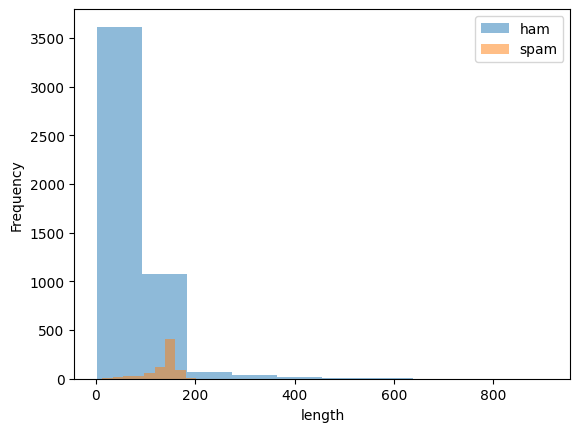

In [150]:
import matplotlib.pyplot as plt

plt.hist(df[df["label"] == "ham"]["length"], alpha=0.5, label="ham")
plt.hist(df[df["label"] == "spam"]["length"], alpha=0.5, label="spam")

plt.xlabel("length")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [151]:
df['words_array'] = df['message'].str.split()
print(df)

     label                                            message  length  \
0      ham  Go until jurong point, crazy.. Available only ...     111   
1      ham                      Ok lar... Joking wif u oni...      29   
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...     155   
3      ham  U dun say so early hor... U c already then say...      49   
4      ham  Nah I don't think he goes to usf, he lives aro...      61   
...    ...                                                ...     ...   
5567  spam  This is the 2nd time we have tried 2 contact u...     160   
5568   ham               Will ü b going to esplanade fr home?      36   
5569   ham  Pity, * was in mood for that. So...any other s...      57   
5570   ham  The guy did some bitching but I acted like i'd...     125   
5571   ham                         Rofl. Its true to its name      26   

                                            words_array  
0     [Go, until, jurong, point,, crazy.., Available...  
1      

In [152]:
words_count_spam = df[df["label"] == "spam"]["words_array"].explode().value_counts()
print(words_count_spam)

words_array
to              607
a               360
your            187
call            185
or              185
               ... 
name,             1
house             1
£750              1
087187272008      1
NOW1!             1
Name: count, Length: 4320, dtype: int64


In [153]:
words_count_ham = df[df["label"] == "ham"]["words_array"].explode().value_counts()
print(words_count_ham)

words_array
to              1538
you             1462
I               1439
the             1029
a                977
                ... 
Pity,              1
So...any           1
suggestions?       1
bitching           1
Rofl.              1
Name: count, Length: 12583, dtype: int64


In [154]:
df["clean_text"] = df["message"].str.lower().str.replace(r'[^\w\s]', '', regex=True)
df["words_array"] = df["clean_text"].str.split()
print(df)

     label                                            message  length  \
0      ham  Go until jurong point, crazy.. Available only ...     111   
1      ham                      Ok lar... Joking wif u oni...      29   
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...     155   
3      ham  U dun say so early hor... U c already then say...      49   
4      ham  Nah I don't think he goes to usf, he lives aro...      61   
...    ...                                                ...     ...   
5567  spam  This is the 2nd time we have tried 2 contact u...     160   
5568   ham               Will ü b going to esplanade fr home?      36   
5569   ham  Pity, * was in mood for that. So...any other s...      57   
5570   ham  The guy did some bitching but I acted like i'd...     125   
5571   ham                         Rofl. Its true to its name      26   

                                            words_array  \
0     [go, until, jurong, point, crazy, available, o...   
1    

In [155]:
words_count_ham = df[df["label"] == "ham"]["words_array"].explode().value_counts()
words_count_spam = df[df["label"] == "spam"]["words_array"].explode().value_counts()
print(words_count_ham)
print(words_count_spam)

words_array
i              2194
you            1841
to             1562
the            1129
a              1064
               ... 
salesman          1
pity              1
soany             1
suggestions       1
bitching          1
Name: count, Length: 7610, dtype: int64
words_array
to              689
a               378
call            347
you             287
your            263
               ... 
bailiff           1
o                 1
house             1
087187272008      1
now1              1
Name: count, Length: 3012, dtype: int64


In [156]:
!pip install nltk


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [157]:
import nltk
from nltk.corpus import stopwords

In [158]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
df['words_array_without_stop'] = df['words_array'].apply(
    lambda words: [word for word in words if word.lower() not in stop_words]
)
print(df)

     label                                            message  length  \
0      ham  Go until jurong point, crazy.. Available only ...     111   
1      ham                      Ok lar... Joking wif u oni...      29   
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...     155   
3      ham  U dun say so early hor... U c already then say...      49   
4      ham  Nah I don't think he goes to usf, he lives aro...      61   
...    ...                                                ...     ...   
5567  spam  This is the 2nd time we have tried 2 contact u...     160   
5568   ham               Will ü b going to esplanade fr home?      36   
5569   ham  Pity, * was in mood for that. So...any other s...      57   
5570   ham  The guy did some bitching but I acted like i'd...     125   
5571   ham                         Rofl. Its true to its name      26   

                                            words_array  \
0     [go, until, jurong, point, crazy, available, o...   
1    

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [159]:
words_count_spam = df[df["label"] == "spam"]["words_array_without_stop"].explode().value_counts()
words_count_ham = df[df["label"] == "ham"]["words_array_without_stop"].explode().value_counts()
print('Ham: ', words_count_ham)
print('Spam: ', words_count_spam)

Ham:  words_array_without_stop
u              985
im             460
2              309
get            303
dont           276
              ... 
salesman         1
pity             1
soany            1
suggestions      1
bitching         1
Name: count, Length: 7482, dtype: int64
Spam:  words_array_without_stop
call            347
free            216
2               173
txt             150
u               147
               ... 
shit              1
bailiff           1
house             1
087187272008      1
now1              1
Name: count, Length: 2904, dtype: int64


Convert text to number (TF_IDF)

In [160]:
#convert every row words of without_stop column into set
# Create a set containing all unique words across all messages
vocabulary = set(word for words in df["words_array_without_stop"] for word in words)
print(vocabulary)
len(vocabulary)


{'itleave', 'mono', 'sportsx', 'buddys', 'announcement', 'rhythm', 'httpwwwetlpcoukexpressoffer', 'soonlots', '449071512431', 'tonite', 'cut', 'buses', 'neglet', 'ttyl', '450', 'blue', 'jamz', 'boltblue', 'asap', 'intha', 'logged', 'store', 'gentleman', '08718720201', 'icky', 'wwwsmsacunatalie2k9', 'spam', 'dload', 'bay', 'im', 'corrupt', 'kthen', 'prices', 'caught', 'ts', 'location', 'rock', '08712460324nat', 'shivratri', 'asa', 'animal', 'totes', 'take', 'carry', 'limping', 'upd8', 'actually', 'hearing', 'infront', 'thanksgiving', 'manky', 'company', 'shot', 'itlet', '4eva', 'gain', 'directors', '2mro', 'musthu', 'diesel', 'freedom', 'dining', 'scouse', 'etc', 'stopcost', 'auction', 'desires', 'vilikkamt', 'anythin', 'minute', 'anythings', 'goin2bed', 'particular', 'homeowners', 'tables', 'yor', 'cancer', 'thasa', 'lolnice', 'kkcongratulation', 'sent', 'bye', 'yrs', 'ltd150mtmsgrcvd18', 'speciale', 'abj', 'xxxxxx', '09063440451', 'charges', 'wet', 'religiously', '50s', 'cashto', 'htt

9454

In [161]:
words = ["free", "prize", "free", "cash"]
word_count = len(words)
print(word_count)

4


In [162]:
word_freq = {}
words = ["free", "prize", "free", "cash"]
for word in words:
    if word in word_freq:
        word_freq[word]+=1
    else: word_freq[word] = 1

print(word_freq)

{'free': 2, 'prize': 1, 'cash': 1}


In [163]:
word_freq_tf= {}
for word in set(words):
    word_freq_tf[word] = word_freq[word] / word_count

print(word_freq_tf)

{'free': 0.5, 'prize': 0.25, 'cash': 0.25}


In [164]:
df["words_count"] = df["words_array_without_stop"].apply(len)
print(df["words_count"])

0       16
1        6
2       23
3        9
4        8
        ..
5567    20
5568     6
5569     4
5570    14
5571     3
Name: words_count, Length: 5572, dtype: int64


In [165]:
def get_word_frequency(words):
    word_frequency = {}

    for word in words:
        if word in word_frequency:
            word_frequency[word] += 1
        else:
            word_frequency[word] = 1

    return word_frequency


df["word_frequency"] = df["words_array_without_stop"].apply(get_word_frequency)
print(df["word_frequency"])

0       {'go': 1, 'jurong': 1, 'point': 1, 'crazy': 1,...
1       {'ok': 1, 'lar': 1, 'joking': 1, 'wif': 1, 'u'...
2       {'free': 1, 'entry': 2, '2': 1, 'wkly': 1, 'co...
3       {'u': 2, 'dun': 1, 'say': 2, 'early': 1, 'hor'...
4       {'nah': 1, 'dont': 1, 'think': 1, 'goes': 1, '...
                              ...                        
5567    {'2nd': 1, 'time': 1, 'tried': 1, '2': 2, 'con...
5568    {'ü': 1, 'b': 1, 'going': 1, 'esplanade': 1, '...
5569    {'pity': 1, 'mood': 1, 'soany': 1, 'suggestion...
5570    {'guy': 1, 'bitching': 1, 'acted': 1, 'like': ...
5571                    {'rofl': 1, 'true': 1, 'name': 1}
Name: word_frequency, Length: 5572, dtype: object


In [166]:
def cal_tf(word_frequency, words_count):
    if words_count == 0:
        return {}
    
    tf = {}
    for word, count in word_frequency.items():
        tf[word] = count / words_count

    return tf

df["tf"] = df.apply(
    lambda row: cal_tf(row["word_frequency"], row["words_count"]),
    axis=1
)

print(df["tf"])

0       {'go': 0.0625, 'jurong': 0.0625, 'point': 0.06...
1       {'ok': 0.16666666666666666, 'lar': 0.166666666...
2       {'free': 0.043478260869565216, 'entry': 0.0869...
3       {'u': 0.2222222222222222, 'dun': 0.11111111111...
4       {'nah': 0.125, 'dont': 0.125, 'think': 0.125, ...
                              ...                        
5567    {'2nd': 0.05, 'time': 0.05, 'tried': 0.05, '2'...
5568    {'ü': 0.16666666666666666, 'b': 0.166666666666...
5569    {'pity': 0.25, 'mood': 0.25, 'soany': 0.25, 's...
5570    {'guy': 0.07142857142857142, 'bitching': 0.071...
5571    {'rofl': 0.3333333333333333, 'true': 0.3333333...
Name: tf, Length: 5572, dtype: object


In [167]:
# IDF
document_frequency = {}

for words in df["words_array_without_stop"]:
    for word in set(words):
        if word in document_frequency:
            document_frequency[word] += 1
        else:
            document_frequency[word] = 1

print(document_frequency)

{'e': 75, 'go': 262, 'point': 13, 'bugis': 7, 'la': 7, 'world': 31, 'amore': 1, 'wat': 92, 'n': 121, 'great': 104, 'cine': 7, 'got': 228, 'crazy': 14, 'jurong': 1, 'buffet': 2, 'available': 16, 'wif': 26, 'oni': 4, 'joking': 6, 'lar': 37, 'ok': 271, 'u': 806, 'tkts': 4, '21st': 3, '87121': 4, 'entry': 21, 'questionstd': 2, 'final': 18, 'ratetcs': 2, 'free': 224, 'text': 170, 'wkly': 14, 'may': 46, '2005': 3, 'fa': 2, '08452810075over18s': 2, '2': 394, 'comp': 11, 'win': 68, 'apply': 31, 'txt': 154, 'cup': 9, 'receive': 34, 'dun': 51, 'early': 31, 'c': 77, 'already': 88, 'hor': 2, 'say': 88, 'nah': 10, 'usf': 11, 'think': 129, 'goes': 25, 'dont': 265, 'though': 26, 'lives': 4, 'around': 57, 'std': 9, 'word': 34, 'chgs': 1, 'send': 187, 'freemsg': 12, 'hey': 110, 'darling': 5, 'back': 146, 'id': 34, 'weeks': 19, 'fun': 30, '150': 39, 'still': 152, 'xxx': 34, 'rcv': 2, 'like': 227, '3': 67, 'tb': 4, 'speak': 33, 'brother': 19, 'aids': 1, 'treat': 16, 'patent': 1, 'even': 60, 'oru': 4, 'ca

In [168]:
import numpy as np

N = len(df)

idf = {}

for word in vocabulary:
    idf[word] = np.log(N / document_frequency[word])

print(idf)

{'itleave': np.float64(7.932362154339751), 'mono': np.float64(7.5268970462315865), 'sportsx': np.float64(8.625509334899697), 'buddys': np.float64(8.625509334899697), 'announcement': np.float64(6.833749865671641), 'rhythm': np.float64(8.625509334899697), 'httpwwwetlpcoukexpressoffer': np.float64(7.932362154339751), 'soonlots': np.float64(8.625509334899697), '449071512431': np.float64(8.625509334899697), 'tonite': np.float64(6.54606779321986), 'cut': np.float64(6.227614062101326), 'buses': np.float64(7.932362154339751), 'neglet': np.float64(8.625509334899697), 'ttyl': np.float64(6.833749865671641), '450': np.float64(6.679599185844383), 'blue': np.float64(6.54606779321986), 'jamz': np.float64(8.625509334899697), 'boltblue': np.float64(8.625509334899697), 'asap': np.float64(6.322924241905651), 'intha': np.float64(8.625509334899697), 'logged': np.float64(8.625509334899697), 'store': np.float64(6.322924241905651), 'gentleman': np.float64(7.5268970462315865), '08718720201': np.float64(7.01607

In [169]:
def calculate_tfidf(tf_dict, idf):
        tfidf = {}
        for word in tf_dict:
            tfidf[word] = tf_dict[word] * idf[word]

        return tfidf

df["tfidf"] = df["tf"].apply(
    lambda tf_dict: calculate_tfidf(tf_dict, idf)
)
print(df["tfidf"])

0       {'go': 0.19107280194616247, 'jurong': 0.539094...
1       {'ok': 0.5038984190033325, 'lar': 0.8357652370...
2       {'free': 0.1397331862193329, 'entry': 0.485303...
3       {'u': 0.42965013164290394, 'dun': 0.5215204113...
4       {'nah': 0.7903655302382063, 'dont': 0.38072243...
                              ...                        
5567    {'2nd': 0.261215597661877, 'time': 0.167115280...
5568    {'ü': 0.6212782558247975, 'b': 0.7470624347513...
5569    {'pity': 2.156377333724924, 'mood': 1.63651694...
5570    {'guy': 0.39214393706932477, 'bitching': 0.616...
5571    {'rofl': 2.5089656820771955, 'true': 1.8022111...
Name: tfidf, Length: 5572, dtype: object


In [170]:
vocabulary = sorted(vocabulary)

In [171]:
#convert to matrix for logistic regression
X_tfidf = np.zeros((len(df), len(vocabulary)))

word_to_index = {word: i for i, word in enumerate(vocabulary)}

for row_idx, tfidf_dict in enumerate(df["tfidf"]):
    for word, value in tfidf_dict.items():
        X_tfidf[row_idx, word_to_index[word]] = value

In [172]:
X_tfidf.shape

(5572, 9454)

In [173]:
df["label"] = df["label"].map({"ham":0, "spam": 1})
print(df["label"])

0       0
1       0
2       1
3       0
4       0
       ..
5567    1
5568    0
5569    0
5570    0
5571    0
Name: label, Length: 5572, dtype: int64


In [174]:
y = df['label'].values
print(y)

[0 0 1 ... 0 0 0]


In [175]:
from sklearn.feature_extraction import DictVectorizer

# 1. df['tf'] ko 2D Numerical Feature Matrix X me convert karo
v = DictVectorizer(sparse=True)
X = v.fit_transform(df["tf"])

# 2. Target labels y
y = df["label"]


In [176]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [177]:
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)

X_train shape: (4457, 9454)
X_test shape:  (1115, 9454)


In [210]:
#it is sparse matrix not numpy we are not converting it because of memory efficiency
from scipy.sparse import hstack

def gd(X, y):
    # Add bias column without converting sparse matrix to dense
    bias = np.ones((X.shape[0], 1))
    X = hstack([bias, X])

    y = y.to_numpy() if hasattr(y, "to_numpy") else y

    weights = np.zeros(X.shape[1])
    lr = 0.5

    for i in range(2500): 
        y_hat = sigmoid(X @ weights)

        gradient = (X.T @ (y - y_hat)) / X.shape[0]

        weights = weights + lr * gradient

    return weights[1:], weights[0]

In [211]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [212]:
coeff_, intercept_ = gd(X_train, y_train)
print(coeff_)
print(intercept_)

[ 0.02969087  0.01134838  0.0117601  ... -0.00891115 -0.66680444
 -0.01526811]
-1.7878010249147556


In [213]:
print(type(X_train))
print(np.ndim(X_train))
print(type(y_train))
print(np.ndim(y_train))

<class 'scipy.sparse._csr.csr_matrix'>
2
<class 'pandas.Series'>
1


In [214]:
z = X_test @ coeff_ + intercept_
y_prob = sigmoid(z)
y_pred = (y_prob >= 0.5).astype(int)

In [215]:
print(y_prob.shape)
print(y_pred.shape)
print(y_pred[:20])

(1115,)
(1115,)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [216]:
print(y_prob[:20])

[0.12588111 0.11065755 0.11796011 0.24079504 0.11291909 0.13665822
 0.14297897 0.13236275 0.1154283  0.13215865 0.14232788 0.11386883
 0.11507745 0.11764106 0.11918398 0.14135552 0.13155472 0.12106789
 0.13908392 0.12390171]


In [217]:
print(np.unique(y_pred, return_counts=True))
print(coeff_[:10])
print(intercept_)

(array([0]), array([1115]))
[0.02969087 0.01134838 0.0117601  0.02141529 0.01606378 0.01964831
 0.         0.0148992  0.04452657 0.02229435]
-1.7878010249147556


In [218]:
print(y_prob.min())
print(y_prob.max())
print(y_prob.mean())

0.04174831158394588
0.33427919565572445
0.13407855156117013


In [219]:
for word in ["free", "prize", "call", "cash", "txt"]:
    idx = vocabulary.index(word)
    print(word, coeff_[idx])

free 1.9411405435460942
prize 0.9927631262638718
call 2.4539994408494477
cash 0.6709632437347258
txt 1.474036073536247


In [220]:
print("Ham average probability:", y_prob[y_test == 0].mean())
print("Spam average probability:", y_prob[y_test == 1].mean())

Ham average probability: 0.1265362211529118
Spam average probability: 0.18297715004692527


In [221]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[966   0]
 [149   0]]


In [222]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print(auc)

0.9574700904581266


In [223]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]:
    y_pred_temp = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_temp)
    recall = recall_score(y_test, y_pred_temp)
    f1 = f1_score(y_test, y_pred_temp)

    print(
        threshold,
        "Precision:", precision,
        "Recall:", recall,
        "F1:", f1
    )

0.1 Precision: 0.14217557251908397 Recall: 1.0 F1: 0.24895572263993315
0.15 Precision: 0.6931216931216931 Recall: 0.8791946308724832 F1: 0.7751479289940828
0.2 Precision: 0.7560975609756098 Recall: 0.2080536912751678 F1: 0.3263157894736842
0.25 Precision: 0.5714285714285714 Recall: 0.026845637583892617 F1: 0.05128205128205128
0.3 Precision: 0.0 Recall: 0.0 F1: 0.0
0.35 Precision: 0.0 Recall: 0.0 F1: 0.0
0.4 Precision: 0.0 Recall: 0.0 F1: 0.0
0.5 Precision: 0.0 Recall: 0.0 F1: 0.0


c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

In [224]:
best_threshold = 0
best_f1 = 0

for threshold in np.arange(0.10, 0.201, 0.001):
    y_pred_temp = (y_prob >= threshold).astype(int)

    f1 = f1_score(y_test, y_pred_temp)

    if f1 > best_f1:
        best_f1 = f1
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

Best threshold: 0.15700000000000006
Best F1: 0.8178913738019169


In [225]:
best_threshold = 0.157

y_pred_final = (y_prob >= best_threshold).astype(int)

In [226]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_final))

[[930  36]
 [ 21 128]]


In [227]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       966
           1       0.78      0.86      0.82       149

    accuracy                           0.95      1115
   macro avg       0.88      0.91      0.89      1115
weighted avg       0.95      0.95      0.95      1115



In [228]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_final)

print("Accuracy:", accuracy)

Accuracy: 0.9488789237668162
